In [48]:
import xarray as xr
from sklearn.model_selection import train_test_split, LeaveOneGroupOut, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import xgboost as xgb
from xgboost import plot_importance
from xarray import DataArray, Dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import rioxarray 
from shapely.geometry import Polygon, Point
import csv



In [49]:
range_id = 1

In [50]:
silo = xr.open_dataset(f"/scratch/tm70/ag9761/iceds_datasets/silo_monthly_rain_iceds_{range_id}_processed.nc")
gcms = xr.open_dataset(f"/scratch/tm70/ag9761/iceds_datasets/preprocessed_dataset_{range_id}_new.nc")

In [51]:
# gcms.sel(latitude=-29.0, longitude=150, model="ecmwf", lead=0)["pr"].values
gcms

<xarray.Dataset> Size: 691MB
Dimensions:    (model: 3, latitude: 181, longitude: 181, time: 293, lead: 6)
Coordinates:
  * model      (model) <U6 72B 'ecmwf' 'ukmo' 'access'
  * latitude   (latitude) float64 1kB -23.0 -23.05 -23.1 ... -31.9 -31.95 -32.0
  * longitude  (longitude) float64 1kB 147.0 147.1 147.1 ... 155.9 156.0 156.0
  * time       (time) datetime64[ns] 2kB 1993-01-01 1993-02-01 ... 2017-05-01
  * lead       (lead) int64 48B 0 1 2 3 4 5
Data variables:
    pr         (model, latitude, longitude, time, lead) float32 691MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

# Preprocessing 
### Selecting Coords

In [52]:
def single_point_data_analysis():
 
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize = (10,10),sharey=True)
    for idx, model in enumerate([silo, gcms.sel(model="ecmwf", lead=0), gcms.sel(model="access", lead=0), gcms.sel(model="ukmo", lead=0)]):
        j = idx % 2
        i = idx // 2
        ax = sns.histplot(model["pr"], ax=axes[i, j])

In [53]:
rows = []

In [54]:
is_single_point = True
grid_point = (np.float64(-29.0), np.float64(150.0))
model_radius = 0.25
silo_radius = 0.25
n_points_inner_circle = 6
radius_inner_circle = 0.6
n_points_outer_circle = 6
radius_outer_circle = 1.04

In [55]:
gcms

<xarray.Dataset> Size: 691MB
Dimensions:    (model: 3, latitude: 181, longitude: 181, time: 293, lead: 6)
Coordinates:
  * model      (model) <U6 72B 'ecmwf' 'ukmo' 'access'
  * latitude   (latitude) float64 1kB -23.0 -23.05 -23.1 ... -31.9 -31.95 -32.0
  * longitude  (longitude) float64 1kB 147.0 147.1 147.1 ... 155.9 156.0 156.0
  * time       (time) datetime64[ns] 2kB 1993-01-01 1993-02-01 ... 2017-05-01
  * lead       (lead) int64 48B 0 1 2 3 4 5
Data variables:
    pr         (model, latitude, longitude, time, lead) float32 691MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [56]:
def construct_circle(origin, n_points, radius, base_angle=0.0, include_origin=False):

    def get_circular_point(angle):
        print(angle)
        return (round(origin[0] + radius * xr.ufuncs.cos(angle), 2), round(origin[1] + radius * xr.ufuncs.sin(angle), 2))
    
    coords = [get_circular_point(base_angle + 2 * i * np.pi / n_points_inner_circle) for i in range(n_points)]
    if include_origin:
        coords.insert(len(coords) // 2, origin)

    return tuple(map(list, zip(*coords)))

construct_circle(grid_point, n_points_inner_circle, radius_inner_circle)
construct_circle(grid_point, n_points_outer_circle, radius_outer_circle, base_angle=np.pi / 8, include_origin=True)

0.0
1.0471975511965976
2.0943951023931953
3.141592653589793
4.1887902047863905
5.235987755982989
0.39269908169872414
1.4398966328953218
2.4870941840919194
3.5342917352885173
4.581489286485114
5.6286868376817125


([np.float64(-28.04),
  np.float64(-28.86),
  np.float64(-29.83),
  np.float64(-29.0),
  np.float64(-29.96),
  np.float64(-29.14),
  np.float64(-28.17)],
 [np.float64(150.4),
  np.float64(151.03),
  np.float64(150.63),
  np.float64(150.0),
  np.float64(149.6),
  np.float64(148.97),
  np.float64(149.37)])

In [57]:
if is_single_point:

    # gcms = gcms.sel(latitude=slice(grid_point[0] - model_radius, grid_point[0] + model_radius), longitude=slice(grid_point[1] - model_radius, grid_point[1] + model_radius))

    ## Inner circle
    points_1 = construct_circle(grid_point, n_points_inner_circle, radius_inner_circle, include_origin=True)
    points_2 = construct_circle(grid_point, n_points_outer_circle, radius_outer_circle, base_angle=np.pi / 6)
    points = (points_1[0] + points_2[0], points_1[1] + points_2[1])
    # points = points_1
    print(points[0])
    print(points[1])
    print(len(points[0]))
    # lat_da = xr.DataArray(points[0], dims="point")
    # lon_da = xr.DataArray(points[1], dims="point")

    def select_circular_points(dataset, points):
        lat_da = xr.DataArray(points[0], dims="point")
        lon_da = xr.DataArray(points[1], dims="point")
        dataset = dataset.sel(latitude=lat_da, longitude=lon_da, method="nearest")
        print(dataset.latitude.values)
        print(dataset.longitude.values)
        dataset = dataset.assign_coords(point=pd.MultiIndex.from_arrays([dataset.latitude.values, dataset.longitude.values], names=["latitude", "longitude"])).unstack("point")
        dataset = dataset.sortby(["latitude", "longitude"])
        return dataset

    # silo = select_circular_points(silo, points)
    # gcms = select_circular_points(gcms, points)

    def dataset_within_radius(dataset, grid_point, radius):
        
        dist = np.sqrt((dataset.latitude - grid_point[0])**2 + (dataset.longitude - grid_point[1])**2)
        mask = dist <= radius

        selected = dataset.where(mask, drop=True)
        return selected

    gcms = dataset_within_radius(gcms, grid_point, model_radius)
    silo = dataset_within_radius(silo, grid_point, model_radius)

    # gcms = select_circular_points(gcms, points)
    # silo_temp = silo_temp.assign_coords(latitude=("point", ),
    #                                     longitude=("point", silo_temp.longitude.values))
    # silo = silo.assign_coords(point=pd.MultiIndex.from_arrays([silo.latitude.values, silo.longitude.values], names=["latitude", "longitude"])).unstack("point")
    # silo = silo.sortby(["latitude", "longitude"])

    # silo = silo.sel(latitude=lat_points, longitude=lon_points, method="nearest").drop_duplicates(dim=["latitude", "longitude"])
    # silo = silo.stack(z=("latitude", "longitude")).sel(z=points).unstack()
    # silo = silo.sortby(["latitude", "longitude"])

0.0
1.0471975511965976
2.0943951023931953
3.141592653589793
4.1887902047863905
5.235987755982989
0.5235987755982988
1.5707963267948966
2.617993877991494
3.665191429188092
4.71238898038469
5.759586531581288
[np.float64(-28.4), np.float64(-28.7), np.float64(-29.3), np.float64(-29.0), np.float64(-29.6), np.float64(-29.3), np.float64(-28.7), np.float64(-28.1), np.float64(-29.0), np.float64(-29.9), np.float64(-29.9), np.float64(-29.0), np.float64(-28.1)]
[np.float64(150.0), np.float64(150.52), np.float64(150.52), np.float64(150.0), np.float64(150.0), np.float64(149.48), np.float64(149.48), np.float64(150.52), np.float64(151.04), np.float64(150.52), np.float64(149.48), np.float64(148.96), np.float64(149.48)]
13


<xarray.Dataset> Size: 2MB
Dimensions:    (model: 3, latitude: 10, longitude: 10, time: 293, lead: 6)
Coordinates:
  * model      (model) <U6 72B 'ecmwf' 'ukmo' 'access'
  * latitude   (latitude) float64 80B -28.75 -28.8 -28.85 ... -29.1 -29.15 -29.2
  * longitude  (longitude) float64 80B 149.8 149.8 149.9 ... 150.1 150.2 150.2
  * time       (time) datetime64[ns] 2kB 1993-01-01 1993-02-01 ... 2017-05-01
  * lead       (lead) int64 48B 0 1 2 3 4 5
Data variables:
    pr         (model, latitude, longitude, time, lead) float32 2MB nan ... nan
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

<xarray.DataArray 'latitude' (latitude: 10)> Size: 80B
array([-28.75, -28.8 , -28.85, -28.9 , -28.95, -29.  , -29.05, -29.1 , -29.15,
       -29.2 ])
Coordinates:
  * latitude  (latitude) float64 80B -28.75 -28.8 -28.85 ... -29.1 -29.15 -29.2
Attributes:
    units:             degrees_north
    standard_name:     latitude
    long_name:         latitude
    stored_direction:  decreasing
    description:       Latitude is positive northward; its units of degree_no...

/jobfs/173462440.gadi-pbs/ipykernel_2475220/3848347176.py:7: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'latitude' ('latitude',) The recommendation is to set join explicitly for this case.
  scatter_plot_data = xr.merge([model, silo.rename_vars({"pr" : "obs_pr"})], compat="override")
/jobfs/173462440.gadi-pbs/ipykernel_2475220/3848347176.py:7: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'longitude' ('longitude',) The recommendation is to set join explicitly for this case.
  scatter_plot_data = xr.merge([mode

                               pr  lead  model  obs_pr
latitude longitude time                               
-29.25   149.75    1993-01-01 NaN     0  ecmwf     NaN
                   1993-02-01 NaN     0  ecmwf     NaN
                   1993-03-01 NaN     0  ecmwf     NaN
                   1993-04-01 NaN     0  ecmwf     NaN
                   1993-05-01 NaN     0  ecmwf     NaN
...                            ..   ...    ...     ...
-28.75   150.25    2017-01-01 NaN     0  ecmwf     NaN
                   2017-02-01 NaN     0  ecmwf     NaN
                   2017-03-01 NaN     0  ecmwf     NaN
                   2017-04-01 NaN     0  ecmwf     NaN
                   2017-05-01 NaN     0  ecmwf     NaN

[129213 rows x 4 columns]
                               pr  lead   model  obs_pr
latitude longitude time                                
-29.25   149.75    1993-01-01 NaN     0  access     NaN
                   1993-02-01 NaN     0  access     NaN
                   1993-03-01 NaN 

/jobfs/173462440.gadi-pbs/ipykernel_2475220/3848347176.py:7: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'latitude' ('latitude',) The recommendation is to set join explicitly for this case.
  scatter_plot_data = xr.merge([model, silo.rename_vars({"pr" : "obs_pr"})], compat="override")
/jobfs/173462440.gadi-pbs/ipykernel_2475220/3848347176.py:7: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'longitude' ('longitude',) The recommendation is to set join explicitly for this case.
  scatter_plot_data = xr.merge([mode

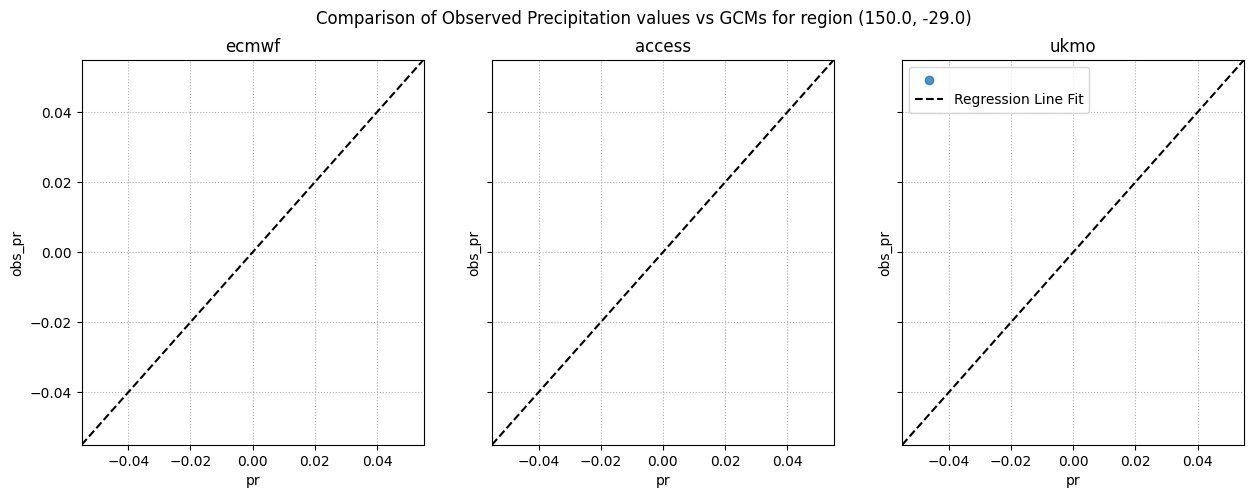

In [59]:
def single_point_data_analysis():
 
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize = (15,5),sharey=True)
    fig.suptitle("Comparison of Observed Precipitation values vs GCMs for region (150.0, -29.0)")
    for idx, model in enumerate([gcms.sel(model="ecmwf", lead=0), gcms.sel(model="access", lead=0), gcms.sel(model="ukmo", lead=0)]):

        scatter_plot_data = xr.merge([model, silo.rename_vars({"pr" : "obs_pr"})], compat="override")
        print(scatter_plot_data.to_dataframe())
        ax = sns.regplot(scatter_plot_data.to_dataframe(), x="pr", y="obs_pr", ax=axes[idx])
        ax.axline((0, 0), slope=1, color='k', ls='--')
        plt.legend(loc='upper left', labels=[None, "Regression Line Fit", None, "Slope 1"])
        ax.grid(True, axis='both', ls=':')
        ax.set_title(model.model.values)

single_point_data_analysis()
plt.show()

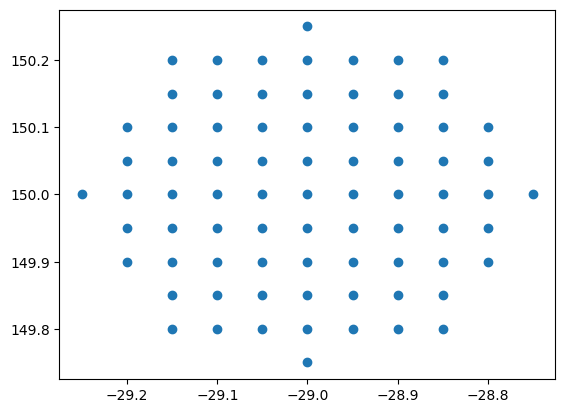

In [60]:
silo_stacked = silo.isel(time=0)["pr"].stack(x=['latitude','longitude'])
silo_df = silo_stacked[silo_stacked.notnull()].to_dataframe().reset_index()
plt.scatter(silo_df["latitude"], silo_df["longitude"])

### Data Analysis

# Feature Engineering

In [61]:
class FeatureEngineering:

    def __init__(self, ds: Dataset, lead_months = 6, window_time = 0):
        self.window_time = window_time
        self.ds = ds.copy()
        self.ds = self.ds.isel(lead=slice(0, lead_months))
        self._process_dates()
    

    def _process_dates(self):
        self.ds["month"] = self.ds["time"].dt.month
        self.ds["year"] = self.ds["time"].dt.year

    def enable_climate_classification(self):
        # https://doi.org/10.1038/s41597-023-02549-6
        climate_class_ds = rioxarray.open_rasterio("koppen_geiger_0p00833333.tif")
        climate_class_ds = climate_class_ds.rename({"x": "longitude", "y": "latitude"})
        climate_class_ds = climate_class_ds.squeeze("band").drop_vars(["band", "spatial_ref"])

        classification = climate_class_ds.sel(latitude=self.ds.latitude, longitude=self.ds.longitude, method="nearest")
        classification = classification.reindex_like(self.ds, method="nearest")
        self.ds["classification"] = classification

    def enable_wet_season_feature(self):
        """Binary switch for dry/wet season"""
        wet_months = [10, 11, 12, 1, 2, 3]
        self.ds["is_wet_month"] = (self.ds["time"].dt.month.isin(wet_months)).astype(int)
    
    def create_lead_time_features(self, params: list[str]):
        for param in params:
            param_features = self._create_lead_time_features(param)
            self.ds = self.ds.drop_vars([param])
            self.ds = xr.merge([self.ds, param_features], join="outer")
        self.ds = self.ds.drop_vars(["lead", "model"])
        return self.ds

    def _create_lead_time_features(self, param: str) -> Dataset:
        """Have separate columns for each lead time forecast."""
        
        param_lead_time = (
            self.ds[param]
            .stack(lead_model=("lead", "model"))
            .groupby("lead_model")
            .map(lambda da: da.squeeze(drop=True))
            .to_dataset(dim="lead_model")
        )

        return param_lead_time.rename_vars({
            k: f"{k[1]}_{k[0]}_{param}"
            for k in param_lead_time.data_vars
        })
    
    def add_obs_window_time(self, period: int):
        for i in range(period):
            self.ds[f"window_{period - 1}"] = silo["pr"].shift(time=period)
    
    # TODO: Add climatology feature

feature_dataset = FeatureEngineering(gcms, lead_months=1) 
# feature_dataset.enable_wet_season_feature()
# feature_dataset.enable_climate_classification()
feature_dataset.create_lead_time_features(["pr"])
# feature_dataset.add_obs_window_time(period=1)

<xarray.Dataset> Size: 359kB
Dimensions:      (latitude: 10, longitude: 10, time: 293)
Coordinates:
  * latitude     (latitude) float64 80B -28.75 -28.8 -28.85 ... -29.15 -29.2
  * longitude    (longitude) float64 80B 149.8 149.8 149.9 ... 150.1 150.2 150.2
  * time         (time) datetime64[ns] 2kB 1993-01-01 1993-02-01 ... 2017-05-01
Data variables:
    month        (time) int64 2kB 1 2 3 4 5 6 7 8 9 10 ... 9 10 11 12 1 2 3 4 5
    year         (time) int64 2kB 1993 1993 1993 1993 ... 2017 2017 2017 2017
    ecmwf_0_pr   (latitude, longitude, time) float32 117kB nan nan ... nan nan
    ukmo_0_pr    (latitude, longitude, time) float32 117kB nan nan ... nan nan
    access_0_pr  (latitude, longitude, time) float32 117kB nan nan ... nan nan
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [62]:
feature_dataset.ds["latitude"] = feature_dataset.ds["latitude"].round(decimals=2)
feature_dataset.ds["longitude"] = feature_dataset.ds["longitude"].round(decimals=2)
silo["longitude"] = silo["longitude"].round(decimals=2)
silo["latitude"] = silo["latitude"].round(decimals=2)

dataset = xr.merge([feature_dataset.ds, silo], join="right")

In [63]:
xr.merge([feature_dataset.ds, silo], join="outer")

<xarray.Dataset> Size: 716kB
Dimensions:      (latitude: 11, longitude: 11, time: 293)
Coordinates:
  * latitude     (latitude) float64 88B -29.25 -29.2 -29.15 ... -28.8 -28.75
  * longitude    (longitude) float64 88B 149.8 149.8 149.8 ... 150.2 150.2 150.2
  * time         (time) datetime64[ns] 2kB 1993-01-01 1993-02-01 ... 2017-05-01
Data variables:
    month        (time) int64 2kB 1 2 3 4 5 6 7 8 9 10 ... 9 10 11 12 1 2 3 4 5
    year         (time) int64 2kB 1993 1993 1993 1993 ... 2017 2017 2017 2017
    ecmwf_0_pr   (latitude, longitude, time) float32 142kB nan nan ... nan nan
    ukmo_0_pr    (latitude, longitude, time) float32 142kB nan nan ... nan nan
    access_0_pr  (latitude, longitude, time) float32 142kB nan nan ... nan nan
    pr           (time, latitude, longitude) float64 284kB nan nan ... nan nan
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [64]:
dataset = dataset.sel(time=slice("1993-01-01", "2016-12-31"))

In [65]:
dataset = dataset.to_dataframe().sort_values(by=['time', "latitude", "longitude"])
if silo_radius > 0:
    rounded_index = pd.MultiIndex.from_tuples(
        [(round(t[0]), round(t[1]), t[2]) for t in dataset.index],
        names=dataset.index.names
    )
    dataset.index = rounded_index

In [66]:
dataset = dataset.dropna(subset=["pr"]) # Could be because points selected before outer merge could be Nan

In [67]:
# TODO: Can be better within feature engineering, then drop NaN rows after creating dataframe 
# dataset = dataset.set_index(["year", "month"]).reset_index()
dataset = dataset.reset_index().drop(columns=["time"])

In [68]:
# xr.ufuncs.log(1 + dataset["pr"])
dataset["pr"] = np.log(dataset["pr"] + 1)

In [69]:
# Temp operations
dataset = dataset[dataset["month"].isin([10, 11, 12, 1, 2, 3])]
# dataset = pd.get_dummies(dataset, columns=["month"], dtype=int)
dataset = dataset.drop(columns=["month", "latitude", "longitude"]) 

In [70]:
dataset

,year,ecmwf_0_pr,ukmo_0_pr,access_0_pr,pr
0,1993,NaN,NaN,NaN,0.848219
1,1993,2.279071,NaN,2.330536,0.785521
2,1993,2.322133,NaN,2.375877,0.784049
3,1993,2.365195,NaN,2.421139,0.850978
4,1993,2.408571,NaN,2.466480,0.849599
...,...,...,...,...,...
22171,2016,0.938534,2.048138,2.435991,0.990859
22172,2016,0.959594,2.021440,2.416660,0.929111
22173,2016,0.980653,1.997591,2.397486,0.871428
22174,2016,1.001556,2.005960,2.389078,0.815936


# Training XGBoost Model

In [71]:
is_yearly_split = True
X = dataset.drop(columns=["pr"])
y = dataset["pr"]
X
y

0        0.848219
1        0.785521
2        0.784049
3        0.850978
4        0.849599
           ...   
22171    0.990859
22172    0.929111
22173    0.871428
22174    0.815936
22175    0.986057
Name: pr, Length: 11088, dtype: float64

In [72]:
def get_xgboost_model():
    xgb_model = xgb.XGBRegressor(objective='reg:squarederror', eval_metric= 'mae', max_depth=5, eta=0.1, 
                             subsample=0.7, colsample_bytree=0.7)

    return xgb_model

def xgboost_train(X_train, y_train):
    params = {
        'objective': 'reg:squarederror',
        'eval_metric': 'mae',
        'max_depth': 5,
        'eta': 0.1,
        'subsample': 0.7,
        'colsample_bytree': 0.7,
        'verbosity': 0
    }

    xgb_model = get_xgboost_model()

    xgb_model.fit(X_train, y_train)

    return xgb_model


def xgboost_predict(xgb_model):
    return xgb_model.predict(X_test)

In [73]:
if is_yearly_split:
    logo = LeaveOneGroupOut()
    groups = dataset["year"]
    
    xgb_model = xgb.XGBRegressor(objective='reg:squarederror')

    y_pred = np.empty(0, dtype=float)

    param_grid = {
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [2],
        'min_child_weight': [1, 3],
        'subsample': [0.2, 0.3, 0.4, 0.7],
        'colsample_bytree': [0.7], 
        'reg_alpha': [1.0],          # L1 regularization
        'reg_lambda': [5.0],         # L2 regularization (increase this)
        'eta': [0.1],
        'n_estimators': [5, 10, 20, 30, 50]
    }

    for train_idx, val_idx in logo.split(X, y, groups):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        xgb_model = get_xgboost_model()
        clf_xgb_model = GridSearchCV(xgb_model, param_grid)


        clf_xgb_model.fit(X_train.drop(columns=["year"]), y_train) # Uses 5-fold cross validation

        y_val_pred = clf_xgb_model.predict(X_val.drop(columns=["year"]))
        # if silo_radius > 0.0:
        #     y_val_pred = y_val_pred[4::9]  # Select only middle points
        #     print(len(y_val_pred))

        print(clf_xgb_model.best_estimator_.feature_importances_)
        y_pred = np.append(y_pred, y_val_pred)
        importance = clf_xgb_model.best_params_

    
    # y_pred = cross_val_predict(
    #     xgb_model,
    #     X.drop(columns=["year"]),
    #     y,
    #     groups=groups,
    #     cv=LeaveOneGroupOut(),
    # )
        
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.05,
        shuffle=False
    )
    print(X_test)
    xgb_model = xgboost_train(X_train, y_train)

    y_pred = xgboost_predict(xgb_model)

[0.47483513 0.12235433 0.4028105 ]
[0.40096095 0.17324615 0.42579293]
[0.24671862 0.13029164 0.6229897 ]
[0.41272664 0.15239869 0.4348747 ]
[0.35915205 0.15362495 0.487223  ]
[0.21396536 0.15067069 0.63536394]
[0.40153793 0.14625596 0.45220616]
[0.358685   0.21087638 0.43043858]
[0.32125115 0.14271386 0.536035  ]
[0.41844505 0.17612045 0.40543446]
[0.36481628 0.20234269 0.43284103]
[0.3690704  0.19959855 0.43133107]
[0.3684678  0.13988477 0.49164742]
[0.4260034  0.16473553 0.40926108]
[0.39158234 0.1991138  0.40930384]
[0.39109865 0.21296063 0.39594072]
[0.30585992 0.22285841 0.47128162]
[0.45084232 0.2343608  0.3147969 ]
[0.4456744  0.24860463 0.30572104]
[0.42703173 0.19202334 0.3809449 ]
[0.4160158  0.2596395  0.32434472]
[0.46075156 0.1895611  0.3496873 ]
[0.39362568 0.22080164 0.38557264]
[0.3180544  0.2898818  0.39206383]


# Evaluation

In [74]:
def single_point_data_analysis(data):
 
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize = (10,10),sharey=True)
    fig.suptitle("Testing of Observed Precipitation values vs GCMs for region (150.0, -29.0)")
    for idx, model in enumerate(["ecmwf_0_pr", "ukmo_0_pr", "access_0_pr", "XGBoost"]):
    # for idx, model in enumerate(["ecmwf_0_pr", "access_0_pr", "XGBoost"]):
        i = idx // 2
        j = idx % 2

        ax = sns.regplot(data, x=model, y="obs_pr", ax=axes[i, j])
        ax.set(xlim=(0, 10))
        ax.axline((0, 0), slope=1, color='k', ls='--')
        plt.legend(loc='upper left', labels=[None, "Regression Line Fit", None, "Slope 1"])
        ax.grid(True, axis='both', ls=':')
        ax.set_title(model)

In [75]:
print(len(y_pred))

11088


In [76]:
y_pred

array([1.04619396, 1.13217115, 1.13217115, ..., 1.04289079, 1.04289079,
       1.04289079])

In [77]:
y_pred = np.exp(y_pred) - 1


In [78]:
y = np.exp(y) - 1


In [84]:
y_pred

array([1.84679545, 2.10238495, 2.10238495, ..., 1.83740751, 1.83740751,
       1.83740751])

In [90]:
if is_yearly_split:
    testing = X.copy()
    testing["XGBoost"] = y_pred
    testing["obs_pr"] = y
    if silo_radius > 0:
        # idx = 8 * (round(silo_radius / 0.05)) + 1
        idx = 77 # len(points[0])
        print(idx)
        testing = testing[(idx//2)::idx]  # Select only middle points
        print(testing)
else:
    testing = X_test.copy()
    testing["XGBoost"] = y_pred
    testing["obs_pr"] = y_test


77
       year  ecmwf_0_pr  ukmo_0_pr  access_0_pr   XGBoost    obs_pr
38     1993    2.455164        NaN     2.410058  2.102385  1.087097
115    1993    1.259171   1.274339     1.905241  1.593131  3.821429
192    1993    0.733469   0.845947     0.598135  1.500726  0.854839
731    1993    1.274592   1.249800     1.577888  1.254572  2.177419
808    1993    2.061948   1.477782     1.875071  1.814819  0.410000
...     ...         ...        ...          ...       ...       ...
21367  2016    0.795790   2.234825     1.175562  1.302467  1.013793
21444  2016    0.619240   1.876672     1.596378  1.302467  0.225806
21983  2016    1.309699   2.141550     1.848868  1.522433  1.632258
22060  2016    1.490616   2.384980     2.001946  2.007295  0.556667
22137  2016    1.099396   2.049218     2.521643  1.789471  1.851613

[144 rows x 6 columns]


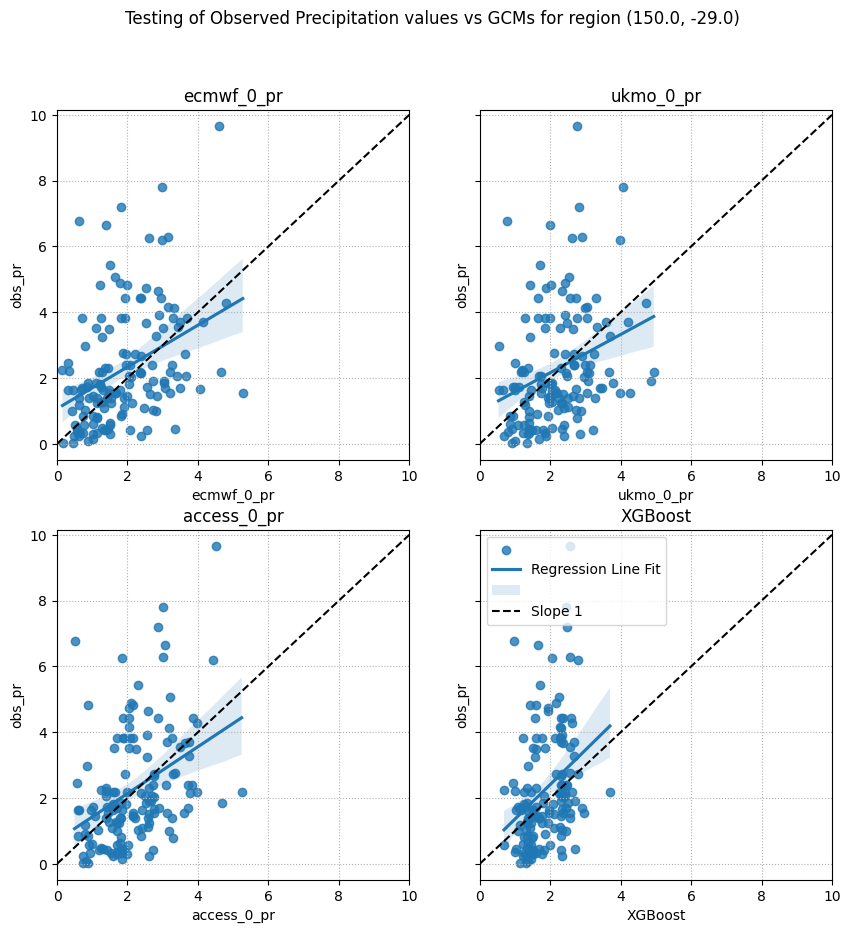

In [91]:
single_point_data_analysis(testing)

In [92]:
testing_temp = testing # .drop(testing.index[-4])
mask = ~np.isnan(testing["obs_pr"]) & ~np.isnan(testing["ukmo_0_pr"])
print(testing_temp["obs_pr"][mask])

model_mae = {
    "XGBoost" : mean_absolute_error(testing_temp["obs_pr"], testing_temp["XGBoost"]),
    "ecmwf" : mean_absolute_error(testing_temp["obs_pr"], testing_temp["ecmwf_0_pr"]),
    "ukmo" : mean_absolute_error(testing["obs_pr"][mask], testing["ukmo_0_pr"][mask]),
    "access" : mean_absolute_error(testing_temp["obs_pr"], testing_temp["access_0_pr"])
}

for model, mae in model_mae.items():
    print(f"{model} MAE: {mae}")

115      3.821429
192      0.854839
731      2.177419
808      0.410000
885      2.380645
           ...   
21367    1.013793
21444    0.225806
21983    1.632258
22060    0.556667
22137    1.851613
Name: obs_pr, Length: 143, dtype: float64
XGBoost MAE: 1.2116104781479455
ecmwf MAE: 1.2209351037624527
ukmo MAE: 1.31161815861804
access MAE: 1.2438191777913703


In [93]:
model_rmse = {
    "XGBoost" : root_mean_squared_error(testing_temp["obs_pr"], testing_temp["XGBoost"]),
    "ecmwf" : root_mean_squared_error(testing_temp["obs_pr"], testing_temp["ecmwf_0_pr"]),
    "ukmo" : root_mean_squared_error(testing["obs_pr"][mask], testing["ukmo_0_pr"][mask]),
    "access" : root_mean_squared_error(testing_temp["obs_pr"], testing_temp["access_0_pr"])
}

for model, rmse in model_rmse.items():
    print(f"{model} RMSE: {rmse}")

XGBoost RMSE: 1.715131506713399
ecmwf RMSE: 1.718213563743861
ukmo RMSE: 1.7311166957964375
access RMSE: 1.6563025801696973


In [43]:
headers = ["Point", "XGBoost_mae", "ecmwf_mae", "ukmo_mae", "access_mae", "XGBoost_rmse", "ecmwf_rmse", "ukmo_rmse", "access_rmse"]
rows.append(
    [grid_point, model_mae["XGBoost"], model_mae["ecmwf"], model_mae["ukmo"], model_mae["access"], model_rmse["XGBoost"], model_rmse["ecmwf"], model_rmse["ukmo"], model_rmse["access"]]
)
# Note: 'newline=""' prevents blank lines between rows on Windows
with open('output.csv', mode='w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file)
    
    writer.writerow(headers)   # Writes a single row (header)
    writer.writerows(rows)     # Writes multiple data rows at once

In [152]:
testing = y_test.to_frame()
# testing["pr_pred"] = y_pred

NameError: name 'y_test' is not defined

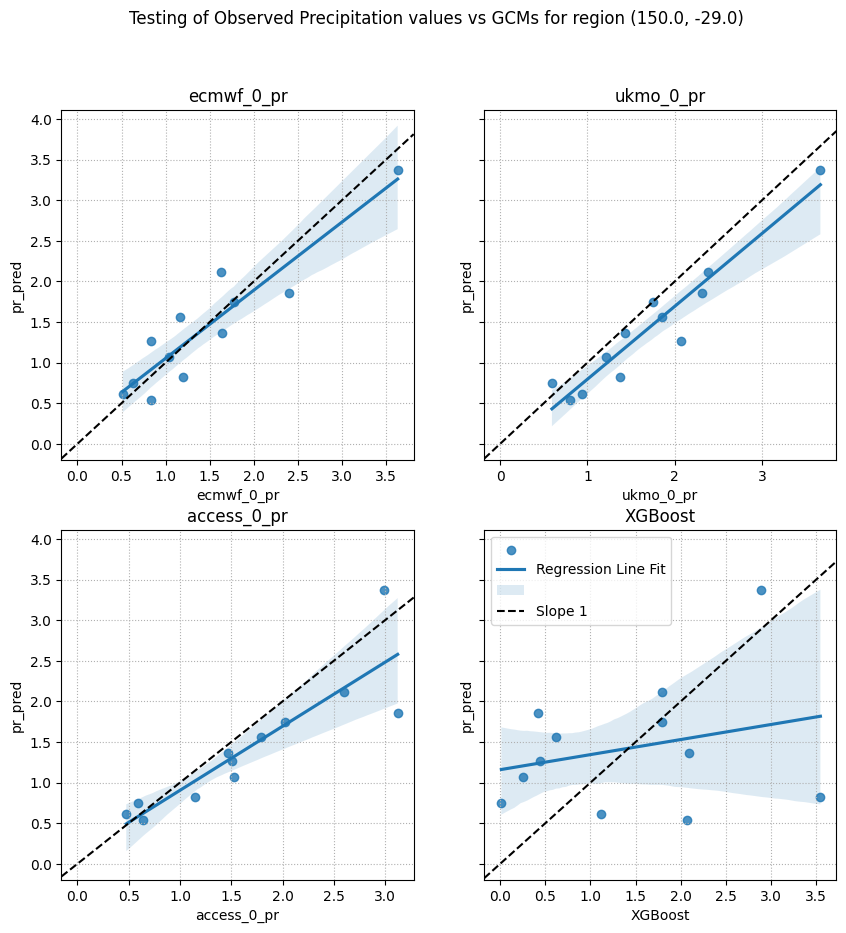

In [ ]:
data = X_test.copy()
data["XGBoost"] = y_pred
data["obs_pr"] = testing["pr"]

single_point_data_analysis(data)

In [28]:
def gcm_mae(pred_pr, obs_pr):
    df = obs_pr.copy()
    df["pred_pr"] = pred_pr
    print(df)
    return df.groupby(["latitude", "longitude"]).apply(lambda dt: mean_absolute_error(dt["pred_pr"], dt["obs_pr"]))

obs_pr = y_test.to_frame(name="obs_pr")
result = gcm_mae(y_pred, obs_pr).to_frame(name="XGBoost")

lead = 0
for model in ["ecmwf", "access", "ukmo"]:
    result[model] = gcm_mae(X_test[f"{model}_{lead}_pr"], obs_pr)
result

        obs_pr   pred_pr
4286  2.606452  1.633655
4287  2.477419  1.738277
4288  5.103333  3.416462
4289  6.656667  5.333120
4290  2.393333  4.073025
...        ...       ...
4507  1.912903  4.554993
4508  1.567742  2.899856
4509  1.851613  2.648596
4510  1.719355  2.518556
4511  1.248387  4.061213

[226 rows x 2 columns]


KeyError: 'latitude'

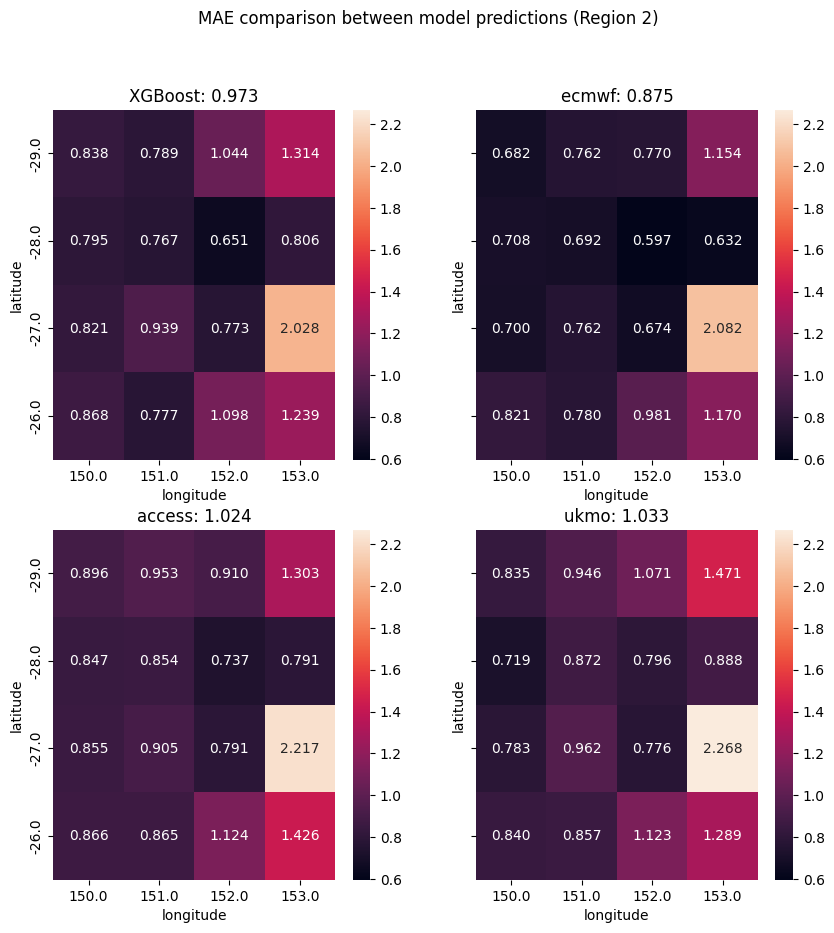

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize = (10,10),sharey=True)

fig.suptitle("MAE comparison between model predictions (Region 2)")

vmin = result.min().min()
vmax = result.max().max()

for idx, model in enumerate(["XGBoost", "ecmwf", "access", "ukmo"]):
    j = idx % 2
    i = idx // 2
    ax = sns.heatmap(result[model].unstack(), annot=True, fmt=".3f", ax=axes[i, j], vmin=vmin, vmax=vmax)
    ax.set_title(f"{model}: {model_mae[model]:.3f}")